# 03 - MAGE exploratory data analysis

MAGE [21]

1. Load
2. Labels
3. Sources
4. The ten main domains
5. Generators and families
6. Prompt method by family
7. Class and domain balance
8. Duplicates
9. Formatting artefacts
10. Normalisation
11. Length
12. Previewing the folds

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from datasets import load_dataset

from logos.project_data.preprocess import normalise_text, preprocess

LABELS = {0: "human", 1: "machine"}

## 1. Load
MAGE is split into train, validation, and test, and each text has a column showing its original split.

In [2]:
# 1. Download MAGE
mage = load_dataset("yaful/MAGE")
print(mage)

# 2. Extract each split into a single dataframe, labelling which split it came from
parts = []
for split_name in ["train", "validation", "test"]:
    part = mage[split_name].to_pandas()
    part["split"] = split_name
    parts.append(part)

# 3. Merge the three into one table
df = pd.concat(parts, ignore_index=True)

print("\n")

print(df.shape)
df.head()

DatasetDict({
    train: Dataset({
        features: ['text', 'label', 'src'],
        num_rows: 319071
    })
    validation: Dataset({
        features: ['text', 'label', 'src'],
        num_rows: 56792
    })
    test: Dataset({
        features: ['text', 'label', 'src'],
        num_rows: 60743
    })
})


(436606, 4)


,text,label,src,split
0,White girls very rarely date Asian men. Even i...,1,cmv_human,train
1,I am a 23 year old male Indian American male. ...,1,cmv_human,train
2,"Take three people, Persons A, B, and C. They l...",1,cmv_human,train
3,(A) Work part-time in high school; Then go to ...,1,cmv_human,train
4,When police introduce a new form of speed prev...,1,cmv_human,train


## 2. Labels
Every source ending in `_human` carries label 1, so it can be inferred that MAGE uses 1 for human, the opposite of this project's convention (0 = human, 1 = machine). The original is kept as `mage_label`, and `label` is flipped.

In [3]:
# 1. Keep MAGE's original label, then flip it to this project's convention
df["mage_label"] = df["label"]
df["label"] = 1 - df["mage_label"]

# 2. Check: every source ending in "_human" should now be 0
is_human = df["src"].str.endswith("_human")
print(df.loc[is_human, "label"].value_counts().to_string())

label
0    152382


## 3. Sources
`src` names follow the conventions `{domain}_human` or `{domain}_machine_{method}_{model}`. Some follow neither, and these are listed so nothing is missed.

In [4]:
# 1. Which pattern does each source name follow
is_machine = df["src"].str.contains("_machine_") & ~df["src"].str.contains("_para")
is_other = ~is_human & ~is_machine

print("human pattern:", is_human.sum())
print("machine pattern:", is_machine.sum())
print("neither:", is_other.sum())

print("\n")

# 2. What are the sources that follow neither pattern
print(df.loc[is_other, "src"].value_counts().to_string())

human pattern: 152382
machine pattern: 281824
neither: 2400


src
cnn_gpt4                200
dialogsum_gpt4          200
imdb_gpt4               200
pubmed_gpt4             200
cnn_human_para          200
cnn_gpt4_para           200
dialogsum_human_para    200
dialogsum_gpt4_para     200
imdb_human_para         200
imdb_gpt4_para          200
pubmed_human_para       200
pubmed_gpt4_para        200


MAGE includes 800 GPT-4 texts from four domains not used elsewhere (CNN/DailyMail, DialogSum, PubMedQA, and IMDb), and 1,600 paraphrased versions of human and GPT-4 texts from those domains. The 800 GPT-4 texts are removed because they do not follow the human pattern.

Each source name is split into its parts: domain, and for machine texts, prompt method and model.

In [5]:
# 1. Extract the domain using the opposite process from above
df["domain"] = df["src"].str.split("_human").str[0].str.split("_machine_").str[0]

# 2. The method and model for only sources that follow the machine pattern
after_machine = df["src"].where(is_machine).str.split("_machine_").str[1]
df["method"] = after_machine.str.split("_", n=1).str[0]
df["model"] = after_machine.str.split("_", n=1).str[1]

print(df["domain"].value_counts().to_string())

domain
yelp                   62776
eli5                   54915
squad                  45763
xsum                   43825
wp                     43609
roct                   41726
hswag                  40276
cmv                    34461
sci_gen                32759
tldr                   32572
cnn                      600
imdb                     600
pubmed                   600
dialogsum                524
cnn_gpt4                 200
dialogsum_gpt4           200
imdb_gpt4                200
pubmed_gpt4              200
cnn_gpt4_para            200
dialogsum_gpt4_para      200
imdb_gpt4_para           200
pubmed_gpt4_para         200


## 4. The ten main domains
MAGE's Testbeds 7 and 8 add four unseen domains (CNN/DailyMail, DialogSum, PubMedQA, IMDb) with GPT-4 texts, and paraphrased versions of them [21]. These test a different question (unseen domains and paraphrasing attacks) and are excluded from the project. The study uses the ten main domains.

In [6]:
main_domains = ["yelp", "eli5", "squad", "xsum", "wp", "roct", "hswag", "cmv", "sci_gen", "tldr"]

# 1. Keep the main domains
in_scope = df["domain"].isin(main_domains) & ~is_other

# 2. What is being excluded, and from which split
excluded = df[~in_scope]
print("excluded:", len(excluded))
print(excluded["split"].value_counts().to_string())

print("\n")

# 3. The in scope corpus
mage_main = df[in_scope].copy()
print("kept:", mage_main.shape)
print(mage_main["label"].map(LABELS).value_counts().to_string())

excluded: 3924
split
test    3924


kept: (432682, 8)
label
machine    281824
human      150858


All 3,924 excluded rows are from MAGE's test split, so its train and validation splits contain only the ten main domains. The in-scope corpus has 432,682 texts: 150,858 human and 281,824 machine (65.1% machine).

## 5. Generators and families
The seven families follow the MAGE authors' grouping by source [21] §5.1. OPT-IML is part of OPT, and T0 sits with BLOOM under BigScience. The paper lists a LLaMA "6B", while in the data it appears as `7B`. `gpt-3.5-turbo` is misspelled as `gpt-3.5-trubo`

In [7]:
families = {
    "OpenAI GPT": ["gpt-3.5-trubo", "text-davinci-002", "text-davinci-003"],
    "LLaMA": ["7B", "13B", "30B", "65B"],
    "GLM-130B": ["GLM130B"],
    "FLAN-T5": ["flan_t5_small", "flan_t5_base", "flan_t5_large", "flan_t5_xl", "flan_t5_xxl"],
    "OPT": ["opt_125m", "opt_350m", "opt_1.3b", "opt_2.7b", "opt_6.7b", "opt_13b", "opt_30b", "opt_iml_max_1.3b", "opt_iml_30b"],
    "BigScience": ["t0_3b", "t0_11b", "bloom_7b"],
    "EleutherAI": ["gpt_j", "gpt_neox"],
}

# 1. Turn the lists into a lookup: model name -> family
model_to_family = {}
for family, models in families.items():
    for model in models:
        model_to_family[model] = family

mage_main["family"] = mage_main["model"].map(model_to_family)

# 2. Every machine text has a family
machine_main = mage_main[mage_main["label"] == 1]
print("machine texts without a family:", machine_main["family"].isna().sum())

# 3. Texts and models per family
summary = machine_main.groupby("family").agg(texts=("text", "size"), models=("model", "nunique"))
summary.sort_values("texts", ascending=False)

machine texts without a family: 0


,texts,models
family,,
OPT,80429,9
OpenAI GPT,66613,3
FLAN-T5,46719,5
LLaMA,37254,4
BigScience,27200,3
EleutherAI,14427,2
GLM-130B,9182,1


The dictionary covers all 27 model names in the data. The model families differ in size: OPT has 80,429 texts from 9 models and 28.5%, while GLM-130B has 9,182 texts from a single model and 3.3%. Training data loss is more for smaller models, but the summary metrics are the same because each family is used equally in the fold. OpenAI GPT has three models with 22,204 texts, and average 22,204 texts each, against 6,839 to 9,454 for every other model. Section 6 examines why.

## 6. Prompt method by family
MAGE's specified and topical prompts were designed for OpenAI models [21]. If only the OpenAI family has them, the prompt style and model family could be confused because the detector could learn the style instead of the generator.

In [8]:
print(pd.crosstab(machine_main["family"], machine_main["method"]).to_string())

method      continuation  specified  topical
family                                      
BigScience         27200          0        0
EleutherAI         14427          0        0
FLAN-T5            46719          0        0
GLM-130B            9182          0        0
LLaMA              37254          0        0
OPT                80429          0        0
OpenAI GPT         28005      18992    19616


Only `OpenAI GPT` has specified (18,992) and topical (19,616) texts. Every other family has continuation texts only. If you hold out OpenAI, you would test an unseen family and two unseen prompt styles at once, and those prompt styles would appear only as OpenAI. Only continuation texts are kept, so every family is generated the same way. This removes 38,608 machine texts (13.7%), leaving 24,3216. OpenAI drops to 28,005 texts (9,335 per model, in line with the other families). The decision is made before any detector is trained on MAGE.

In [9]:
# 1. Keep continuation prompts only (human texts have no method, so they are kept too)
is_human_row = mage_main["method"].isna()
is_continuation = mage_main["method"] == "continuation"
mage_main = mage_main[is_human_row | is_continuation].copy()

# 2. Rebuild the machine-only table from the filtered corpus
machine_main = mage_main[mage_main["label"] == 1]

# 3. Check the new counts
print("kept:", len(mage_main))
print("\n")
print(mage_main["label"].map(LABELS).value_counts().to_string())
print("\n")
print(machine_main["family"].value_counts().to_string())

kept: 394074


label
machine    243216
human      150858


family
OPT           80429
FLAN-T5       46719
LLaMA         37254
OpenAI GPT    28005
BigScience    27200
EleutherAI    14427
GLM-130B       9182


After filtering, 394,074 texts remain: 150,858 human and 243,216 machine (61.7% machine). OpenAI GPT now has 28,005 texts, in line with the other families.

## 7. Class and domain balance

In [10]:
# 1. Human and machine texts per domain
print(pd.crosstab(mage_main["domain"], mage_main["label"].map(LABELS)).to_string())

print("\n")

# 2. Machine texts per domain and family
print(pd.crosstab(machine_main["domain"], machine_main["family"]).to_string())

label    human  machine
domain                 
cmv       9062    20618
eli5     23008    25927
hswag     9709    25351
roct      9846    25883
sci_gen   9505    23254
squad    20852    24911
tldr      7887    20044
wp       12588    25024
xsum     11265    26564
yelp     37136    25640


family   BigScience  EleutherAI  FLAN-T5  GLM-130B  LLaMA   OPT  OpenAI GPT
domain                                                                     
cmv            2298        1248     3864       790   3130  6894        2394
eli5           2904        1637     4886       978   3911  8667        2944
hswag          2899        1531     4921       975   3895  8192        2938
roct           2940        1596     4926       988   3943  8532        2958
sci_gen        2677         911     4712       800   3721  7855        2578
squad          2850        1281     4857       981   3877  8098        2967
tldr           2277        1212     3798       753   3039  6669        2296
wp             2943       

Machine texts are spread fairly evenly across domains (20,044 to 26,564), but human texts are not (from 7,886 (tldr) to 37,136 (yelp)). Yelp is the only domain with more human than machine texts (59.2% human, against 27.7% for hswag), and supplies 24.6% of all human texts. Domain is therefore slightly associated with the label, and yelp has the most weight in any threshold calibrated on MAGE human texts. As with HC3, the domains are left at their natural sizes rather than evened out, and results are reported for each domain as well as overall, so a large domain cannot hide a poor result in a small one.

Each family is tested across all ten domains, so differences between folds are not driven by domain mix.

## 8. Duplicates

In [11]:
# 1. Exact duplicate texts, by class
is_duplicate = mage_main["text"].duplicated()
print("duplicate texts:", is_duplicate.sum())
print(mage_main.loc[is_duplicate, "label"].map(LABELS).value_counts().to_string())

print("\n")

# 2. Texts that appear under both labels
labels_per_text = mage_main.groupby("text")["label"].nunique()
print("texts labelled both human and machine:", (labels_per_text > 1).sum())

# 3. The most repeated texts
mage_main["text"].value_counts().head(10)

duplicate texts: 52
label
human      50
machine     2


texts labelled both human and machine: 0


text
I'm seeing this shit a lot nowadays. Internet people are angry about something, take their hate to social media and it ruins people's lives. I'm really sick of this. [Tyranny of shrill minority] is the term I really like. I'm sure majority of reddit will pat each other on the back how "they did it," how they overthrow a tyrant and reddit will be back to their good ol' days. What a load of shit. Reddit turned into a mob without any grounds to be so angry about Ellen Pao. - Her lawsuit has nothing to do with reddit. You might not like it, but that's about it. Plenty of CEO's are dicks or plain abhorrent people, that have nothing to do with their ability to run a company - She didn't fire Victoria - Nobody knows why Victoria was fired. It's none of your business anyway - FPH definitelly wasn't the first time reddit ban a subreddit, harassing and brigading people outside of the sub was always reason for ban, I would like to turn your attention to [this] . Do you think this is okay? - 

52 texts appear twice (50 human, 2 machine). No text appears under both labels. Repeats are dropped, keeping the first copy, as with HC3. Seven of the ten repeated texts end in the CMV moderators' automatic footnote ("Hello, users of CMV! …"), which is added by the subreddit, not the writer. The footnote frequency by class is checked below.


In [12]:
# 1. Which texts contain the CMV moderators' footnote
has_footnote = mage_main["text"].str.contains("This is a footnote from", regex=False)

# 2. Count them by domain and class
print(pd.crosstab([mage_main["domain"], mage_main["label"].map(LABELS)], has_footnote).to_string())

text             False  True 
domain  label                
cmv     human     5890   3172
        machine  20618      0
eli5    human    23008      0
        machine  25927      0
hswag   human     9709      0
        machine  25351      0
roct    human     9846      0
        machine  25883      0
sci_gen human     9505      0
        machine  23254      0
squad   human    20852      0
        machine  24911      0
tldr    human     7887      0
        machine  20044      0
wp      human    12588      0
        machine  25024      0
xsum    human    11265      0
        machine  26564      0
yelp    human    37136      0
        machine  25640      0


3,172 of 9,062 human CMV texts end with the moderators' automatic footnote, including 21 themed or parody versions. No machine text has it, and no other domain has it. The footnote is removed before de-duplication, since it can make texts identical.

In [13]:
# 1. Remember which texts have the themed footnote, to check them afterwards
themed = mage_main["text"].str.contains("Hello, people of the past. This is a footnote", regex=False)

# 2. Remove the footnote: from its greeting up to "Happy CMVing!", or to the end of the text
footnote_pattern = r"(?s)\s*Hello, [^.!]*[.!] This is a footnote from.*?(?:Happy CMVing!|$)\s*"
mage_main["text"] = mage_main["text"].str.replace(footnote_pattern, " ", regex=True).str.strip()

# 3. Check: no footnote left anywhere
print("footnotes left:", mage_main["text"].str.contains("This is a footnote from", regex=False).sum())
print("'Happy CMVing' left:", mage_main["text"].str.contains("Happy CMVing", regex=False).sum())

print("\n")

# 4. The themed texts should now end with the writer's own words
for themed_text in mage_main.loc[themed, "text"].head(5):
    print("...", themed_text[-100:])

footnotes left: 0
'Happy CMVing' left: 0


... go, change is change is impossible because movement is impossible. QED CMV, followers of Heraclitus.
...  himself with traitors such as Paul Revere should be arrested and hung for treason immediately. CMV.
... rgetting the presence of that piece of rotten wood in the middle of our beautiful central courtyard.
... e then? I think if my wife can't give me a son I should be able to find a woman who can. Am I wrong?
... own upon the brow of labor this crown of thorns. You shall not crucify mankind upon a cross of gold.


The pattern accepts footnotes with "CMV" missing, footnotes cut off before "Happy CMVing!", two parody versions, and 19 themed versions beginning "Hello, people of the past." None remains.

In [14]:
# 1. Drop repeated texts, keeping the first copy of each
mage_main = mage_main.drop_duplicates(subset="text").copy()

# 2. Rebuild the machine-only table
machine_main = mage_main[mage_main["label"] == 1]

# 3. Check the new counts
print("kept:", len(mage_main))
print("\n")
print(mage_main["label"].map(LABELS).value_counts().to_string())

kept: 394022


label
machine    243214
human      150808


De-duplication after footnote removal drops the same 52 repeats, so removal created no new duplicates. 394,022 texts remain: 150,808 human and 243,214 machine.

## 9. Formatting artefacts
The same signals as `01` §4. MAGE's authors normalised punctuation [21], and some of its human texts come from the same sources as HC3's (ELI5), so this checks whether any tokenisation artefacts remain.

In [15]:
signals = {
    "split n't": r" n't\b",
    "split 's / 're / 've / 'll / 'd": r" '(?:s|re|ve|ll|d)\b",
    "space before comma": r" ,",
    "spaced dollar": r"\$ \d",
    "spaced percent": r"\d %",
    "URL placeholder": r"URL_\d+",
    "spaced quotes": r'\s"\s',
    "spaced hyphen": r"\w - \w",
    "spaced asterisks": r"\s\*\s",
    "square brackets": r"\[",
    "slash": r"/",
}

def signal_rates(df):
    hits = pd.DataFrame({name: df["text"].str.contains(p) for name, p in signals.items()})
    return hits.groupby([df["label"].map(LABELS), df["domain"]]).mean()

signal_rates(mage_main)

split n't  split 's / 're / 've / 'll / 'd  \
label   domain                                                
human   cmv       0.000000                         0.001215   
        eli5      0.000000                         0.001304   
        hswag     0.000000                         0.000000   
        roct      0.000000                         0.000000   
        sci_gen   0.000000                         0.002420   
        squad     0.000000                         0.000336   
        tldr      0.000000                         0.000000   
        wp        0.000000                         0.000477   
        xsum      0.000000                         0.000089   
        yelp      0.000000                         0.000135   
machine cmv       0.000000                         0.002813   
        eli5      0.000000                         0.002623   
        hswag     0.000039                         0.001657   
        roct      0.000077                         0.002511   
        sci_gen   0.000000                         0.001591   
        squad     0.000000                         0.002529   
        tldr      0.000000                         0.003891   
        wp        0.000040                         0.006314   
        xsum      0.000075                         0.003200   
        yelp      0.000156                         0.003276   

                 space before comma  spaced dollar  spaced percent  \
label   domain                                                       
human   cmv                0.036350            0.0             0.0   
        eli5               0.004390            0.0             0.0   
        hswag              0.001443            0.0             0.0   
        roct               0.000203            0.0             0.0   
        sci_gen            0.134891            0.0             0.0   
        squad              0.015551            0.0             0.0   
        tldr               0.000000            0.0             0.0   
        wp                 0.034636            0.0             0.0   
        xsum               0.001864            0.0             0.0   
        yelp               0.001050            0.0             0.0   
machine cmv                0.023961            0.0             0.0   
        eli5               0.015274            0.0             0.0   
        hswag              0.009625            0.0             0.0   
        roct               0.011591            0.0             0.0   
        sci_gen            0.047347            0.0             0.0   
        squad              0.036692            0.0             0.0   
        tldr               0.013271            0.0             0.0   
        wp                 0.018063            0.0             0.0   
        xsum               0.013477            0.0             0.0   
        yelp               0.010452            0.0             0.0   

                 URL placeholder  spaced quotes  spaced hyphen  \
label   domain                                                   
human   cmv                  0.0       0.008065       0.111148   
        eli5                 0.0       0.018298       0.171158   
        hswag                0.0       0.046682       0.000000   
        roct                 0.0       0.000000       0.003153   
        sci_gen              0.0       0.003157       0.078598   
        squad                0.0       0.001728       0.082601   
        tldr                 0.0       0.000000       0.008623   
        wp                   0.0       0.228630       0.161741   
        xsum                 0.0       0.007901       0.423879   
        yelp                 0.0       0.000027       0.097883   
machine cmv                  0.0       0.007470       0.191153   
        eli5                 0.0       0.012497       0.174104   
        hswag                0.0       0.042720       0.184293   
        roct                 0.0       0.007804       0.149055   
        sci_gen              0.0 

Unlike HC3, MAGE does not perform any corpus-wide tokenisation: split contractions, spaced currency and percentages, URL placeholders and asterisks are absent or near zero in both classes. MAGE removed all slashes, since there are no slashes in any text. This is symmetric and so contains no label information. Two artefacts are one-sided: spaced quotes in wp (22.9% of human texts vs 5.5% of machine) and a space before commas in sci_gen (13.5% vs 4.7%) consistent with WritingPrompts’ original tokenisation and with removed citations. Both are subject to the normalisation present and are rechecked in 10. Both classes have spaced hyphens and square brackets whose direction is domain dependent (spaced hyphens occur more often in machine text in nine out of ten domains), so they are treated as writing style and are retained.

## 10. Normalisation
The same `normalise_text` as HC3 is applied to every text.

In [16]:
# 1. Apply the same normalisation used for HC3
normalised = mage_main.assign(text=mage_main["text"].apply(normalise_text))

# 2. Re-check the formatting signals
signal_rates(normalised)

split n't  split 's / 're / 've / 'll / 'd  \
label   domain                                                
human   cmv            0.0                         0.000000   
        eli5           0.0                         0.000261   
        hswag          0.0                         0.000000   
        roct           0.0                         0.000000   
        sci_gen        0.0                         0.000105   
        squad          0.0                         0.000048   
        tldr           0.0                         0.000000   
        wp             0.0                         0.000000   
        xsum           0.0                         0.000000   
        yelp           0.0                         0.000000   
machine cmv            0.0                         0.000049   
        eli5           0.0                         0.000193   
        hswag          0.0                         0.000000   
        roct           0.0                         0.000116   
        sci_gen        0.0                         0.000129   
        squad          0.0                         0.000161   
        tldr           0.0                         0.000249   
        wp             0.0                         0.000000   
        xsum           0.0                         0.000038   
        yelp           0.0                         0.000000   

                 space before comma  spaced dollar  spaced percent  \
label   domain                                                       
human   cmv                     0.0            0.0             0.0   
        eli5                    0.0            0.0             0.0   
        hswag                   0.0            0.0             0.0   
        roct                    0.0            0.0             0.0   
        sci_gen                 0.0            0.0             0.0   
        squad                   0.0            0.0             0.0   
        tldr                    0.0            0.0             0.0   
        wp                      0.0            0.0             0.0   
        xsum                    0.0            0.0             0.0   
        yelp                    0.0            0.0             0.0   
machine cmv                     0.0            0.0             0.0   
        eli5                    0.0            0.0             0.0   
        hswag                   0.0            0.0             0.0   
        roct                    0.0            0.0             0.0   
        sci_gen                 0.0            0.0             0.0   
        squad                   0.0            0.0             0.0   
        tldr                    0.0            0.0             0.0   
        wp                      0.0            0.0             0.0   
        xsum                    0.0            0.0             0.0   
        yelp                    0.0            0.0             0.0   

                 URL placeholder  spaced quotes  spaced hyphen  \
label   domain                                                   
human   cmv                  0.0       0.001436       0.111148   
        eli5                 0.0       0.004303       0.171158   
        hswag                0.0       0.008450       0.000000   
        roct                 0.0       0.000000       0.003153   
        sci_gen              0.0       0.000210       0.078598   
        squad                0.0       0.000192       0.082601   
        tldr                 0.0       0.000000       0.008623   
        wp                   0.0       0.019145       0.161741   
        xsum                 0.0       0.000533       0.423879   
        yelp                 0.0       0.000000       0.097883   
machine cmv                  0.0       0.002910       0.191153   
        eli5                 0.0       0.002584       0.174104   
        hswag                0.0       0.009388       0.184293   
        roct                 0.0       0.001777       0.149055   
        sci_gen              0.0 

In [17]:
# 1. Word counts before and after
before = mage_main["text"].str.split().str.len()
after = normalised["text"].str.split().str.len()

# 2. Share of texts changed by normalisation, by class
changed = mage_main["text"] != normalised["text"]
print(changed.groupby(mage_main["label"].map(LABELS)).mean().to_string())

print("\n")

# 3. Normalisation should never lengthen a text
print("texts made longer:", (after > before).sum())

# 4. Words removed, by class
(before - after).groupby(mage_main["label"].map(LABELS)).describe()

label
human      0.214186
machine    0.221875


texts made longer: 190


,count,mean,std,min,25%,50%,75%,max
label,,,,,,,,
human,150808.0,1.084956,4.622915,-18.0,0.0,0.0,0.0,190.0
machine,243214.0,0.938684,6.366660,-105.0,0.0,0.0,0.0,1616.0


The two one-sided artefacts are then normalised: spaced quotes in wp fall from 22.9% to 1.9% of human texts (machine 1.0%) and spaces before commas fall to zero in every domain. Normalisation changed 21.4% of human and 22.2% of machine texts, deleting a mean of 1.08 and 0.94 words respectively (median 0 for both), so it doesn't shorten one class more than the other, unlike HC3. Quote pairing misassigns quotes in 190 texts (112 human, 78 machine; 0.074% and 0.032% of each class) mixing attached and spaced quotation marks, adding detached quote tokens. No words are lost, the effect is too small to bias either class and the shared normalisation remains unchanged so both corpora are processed in the same way. The largest reductions are machine outputs of repeated punctuation, where loose quote and comma tokens are combined; these are real generator outputs, and are kept.

## 11. Length
Measured on normalised text. This decides whether MAGE's training folds need length matching, as HC3's did.

In [18]:
lengths = normalised.assign(n_words=after)
lengths["group"] = lengths["family"].fillna("human")

# 1. By class
display(lengths.groupby(lengths["label"].map(LABELS))["n_words"].describe())

# 2. Human texts next to each family
lengths.groupby("group")["n_words"].describe()

,count,mean,std,min,25%,50%,75%,max
label,,,,,,,,
human,150808.0,196.572330,256.742686,1.0,57.0,118.0,225.0,10127.0
machine,243214.0,228.553048,250.848417,6.0,50.0,113.0,297.0,1043.0


,count,mean,std,min,25%,50%,75%,max
group,,,,,,,,
BigScience,27199.0,140.909923,193.201401,8.0,36.00,49.0,165.0,999.0
EleutherAI,14427.0,312.871976,297.974213,11.0,90.00,164.0,487.0,963.0
FLAN-T5,46718.0,52.783424,51.142122,7.0,34.00,40.0,51.0,905.0
GLM-130B,9182.0,519.255718,302.840344,6.0,201.25,626.0,793.0,976.0
LLaMA,37254.0,422.046572,259.234555,11.0,175.00,394.0,679.0,1008.0
OPT,80429.0,249.161086,245.841582,7.0,79.00,143.0,317.0,1043.0
OpenAI GPT,28005.0,151.560293,140.616649,9.0,73.00,109.0,174.0,934.0
human,150808.0,196.572330,256.742686,1.0,57.00,118.0,225.0,10127.0


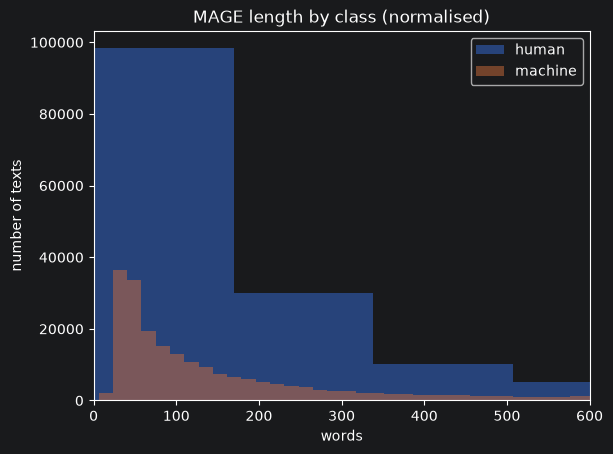

under 10 words: 1623
group
human         1573
FLAN-T5         32
BigScience      11
GLM-130B         4
OpenAI GPT       2
OPT              1


In [19]:
# 1. Histogram: human vs machine
for name, group in lengths.groupby(lengths["label"].map(LABELS)):
    plt.hist(group["n_words"], bins=60, alpha=0.5, label=name)

plt.xlim(0, 600)
plt.xlabel("words")
plt.ylabel("number of texts")
plt.legend()
plt.title("MAGE length by class (normalised)")
plt.show()

# 2. How many texts the 10-word minimum would remove, by group
short = lengths["n_words"] < 10
print("under 10 words:", short.sum())
print(lengths.loc[short, "group"].value_counts().to_string())

In [20]:
# 1. Median length by domain, human vs machine
print(lengths.groupby(["domain", lengths["label"].map(LABELS)])["n_words"].median().unstack().to_string())

print("\n")

# 2. Human texts longer than the longest machine text
longest_machine = lengths.loc[lengths["label"] == 1, "n_words"].max()
print("longest machine text:", longest_machine)
print("human texts longer:", (lengths.loc[lengths["label"] == 0, "n_words"] > longest_machine).sum())

label    human  machine
domain                 
cmv      198.0    107.0
eli5     161.0     89.0
hswag     27.0     95.0
roct      44.0    110.0
sci_gen  159.0    146.0
squad    108.0    177.0
tldr      78.0    122.0
wp       433.0    165.0
xsum     290.0    105.0
yelp      97.5     84.0


longest machine text: 1043
human texts longer: 2449


When pooled, human and machine lengths are similar (median 118 and 113 words), but this masks large within-domain differences in both directions: humans write longer than machines in wp (median 165 against 118) and xsum (median 105 against 290), and shorter in hswag (median 95 against 27) and roct (median 110 against 44). No machine text exceeds 1,043 words, the maximum for a generation, but 2,449 human texts (1.62%) do. Families also differ greatly, ranging from a median of 40 words (FLAN-T5) to 626 (GLM-130B). Thus, in leave-one-family-out, length alone would make some held-out families look human and others machine. Following HC3, MAGE training folds are therefore length-matched within domain: each machine text is paired with a human text from the same domain within ±20% of its length, since MAGE has no shared question identifiers. Retention is reported per domain in `04`.

In [21]:
# 1. Build the final corpus with the same function used for HC3: normalise, drop duplicates, keep texts of 10 words or more
mage_final = preprocess(mage_main)

# 2. Rebuild the machine-only table from the final corpus
machine_final = mage_final[mage_final["label"] == 1]

# 3. How many texts remain, by class
print("final:", len(mage_final))
print(mage_final["label"].map(LABELS).value_counts().to_string())

final: 392385
label
machine    243160
human      149225


## 12. Previewing the folds
Each fold trains on MAGE's train split, calibrates τ* on human texts from its validation split, and is evaluated on its test split, so every condition is tested on the same texts. In a LOFO fold one family is withheld from training; in a LOMO fold one model is withheld, and training is subsampled to the size of its family's LOFO fold. Counts are before length matching, which reduces training further.

In [22]:
# 1. Which MAGE split each family's machine texts are in
print(pd.crosstab(machine_final["family"], machine_final["split"]).to_string())

train_machine = machine_final[machine_final["split"] == "train"]
test_machine = machine_final[machine_final["split"] == "test"]

# 2. LOFO: train on the other six families, test on the held-out family
lofo_preview = []
for lofo_family in families:
    lofo_preview.append({
        "held-out family": lofo_family,
        "training machine texts": (train_machine["family"] != lofo_family).sum(),
        "test machine texts": (test_machine["family"] == lofo_family).sum(),
    })
lofo_table = pd.DataFrame(lofo_preview).set_index("held-out family")
print(lofo_table.to_string())

# 3. LOMO: hold out one model; training is subsampled to its family's LOFO size
lomo_models = {
    "OpenAI GPT": "gpt-3.5-trubo",
    "LLaMA": "65B",
    "FLAN-T5": "flan_t5_xxl",
    "OPT": "opt_iml_30b",
    "BigScience": "bloom_7b",
    "EleutherAI": "gpt_neox",
}
lomo_preview = []
for lomo_family, lomo_model in lomo_models.items():
    lomo_preview.append({
        "held-out model": lomo_model,
        "available training texts": (train_machine["model"] != lomo_model).sum(),
        "subsampled to": lofo_table.loc[lomo_family, "training machine texts"],
        "test machine texts": (test_machine["model"] == lomo_model).sum(),
    })
print(pd.DataFrame(lomo_preview).to_string())

print("\n")

# 4. Human texts by MAGE's original split
human_final = mage_final[mage_final["label"] == 0]
print(human_final["split"].value_counts().to_string())

split       test  train  validation
family                             
BigScience  2692  21789        2706
EleutherAI  1442  11585        1400
FLAN-T5     4658  37395        4632
GLM-130B     919   7340         919
LLaMA       3710  29844        3699
OPT         8012  64414        8001
OpenAI GPT  2790  22424        2789
                 training machine texts  test machine texts
held-out family                                            
OpenAI GPT                       172367                2790
LLaMA                            164947                3710
GLM-130B                         187451                 919
FLAN-T5                          157396                4658
OPT                              130377                8012
BigScience                       173002                2692
EleutherAI                       183206                1442
  held-out model  available training texts  subsampled to  test machine texts
0  gpt-3.5-trubo                    187159         172367 

Preprocessing with the same function as HC3 leaves 392,385 texts (149,225 human, 243,160 machine): 1,623 under 10 words and 14 duplicates created by normalisation are removed. Every family appears in all three of MAGE's splits, so MAGE's original splits are kept: folds train on the train split, calibrate τ* on human texts from the validation split (28,407 texts, so the threshold is set by the 284 highest-scoring), and are evaluated on the test split. All conditions are therefore evaluated on the same texts. τ* uses human text only, which is available at deployment, while text from an unseen generator is not. LOFO test sets range from 919 machine texts (GLM-130B) to 8,012 (OPT), and LOMO test sets from 680 (gpt_neox) to 950 (gpt-3.5-turbo), so estimates on the smallest targets are the least precise. Length matching pairs each machine training text with one human training text, capping training at 92,566 pairs, and LOMO training sets are subsampled to their family's LOFO size after matching.

## Observations

### Labels
MAGE labels human text 1. Labels are flipped at load so that 0 = human and 1 = machine, matching HC3.

### Scope
3,924 rows from MAGE's 7 and 8 testbeds (four unseen domains, with GPT-4 texts and paraphrases), all in its test split, are excluded. The ten main domains remain (432,682 texts).

### Families
All 27 generators map onto the authors' seven model sets, from one model (GLM-130B) to nine (OPT).

### Prompt methods
Topical and specified prompts exist only for OpenAI GPT, which would confound prompt style with family. Only continuation texts are kept, removing 38,608 machine texts and leaving 394,074.

### Balance
61.7% of texts are machine. Machine texts are spread evenly across domains, but human texts range from 7,887 (tldr) to 37,136 (yelp). Every family covers every domain. The skew is retained and results are disaggregated by domain.

### Duplicates and collection artefacts
The CMV moderators' footnote ends 3,172 human CMV texts (35.0%) and no machine text; it is removed and the rest of each text kept. 52 exact repeats (50 human, 2 machine) are then dropped. No text carries both labels.

### Formatting artefacts
Unlike HC3, there is no corpus-wide tokenisation. Two artefacts are one-sided: spaced quotes in wp (22.9% of human texts against 5.5% of machine) and spaces before commas in sci_gen (13.5% against 4.7%). Slashes are absent from all texts, which carries no label information. Spaced hyphens and square brackets occur in both classes and are kept as writing style.

### Normalisation
The HC3 normalisation removes both one-sided artefacts and, unlike on HC3, changes the two classes almost equally: 21.4% of human and 22.2% of machine texts, with a mean of 1.08 and 0.94 words removed. Quote mis-pairing affects 190 texts (0.074% of human, 0.032% of machine), too few to bias either class, so the shared function is left unchanged.

### Length
Pooled medians are similar (118 words human, 113 machine), but within domains the classes differ by up to 3.5 times in both directions, no machine text exceeds 1,043 words, and family medians range from 40 (FLAN-T5) to 626 (GLM-130B). Training folds are therefore length-matched within domain (±20%); calibration and test keep natural lengths.

### Final corpus and folds
Preprocessing leaves 392,385 texts (149,225 human, 243,160 machine). MAGE's original splits are kept: the train split for training, human texts from the validation split (28,407) for τ*, and the test split for evaluation. LOFO test sets range from 919 to 8,012 machine texts, and LOMO test sets from 680 to 950.